<a href="https://colab.research.google.com/github/jeyner99/Integracion-de-datos-y-prospectiva/blob/main/Reto_final_Jeyner_Casta%C3%B1o_Brainer_Arango.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import scipy.stats as stats
warnings.filterwarnings('ignore')

In [ ]:
def caracterizacion(LDA):

    NI = 10 #Número de intervalos en los cuales quiero agrupar los datos
    counts, Limits = np.histogram(LDA, bins = NI) #Agrupar los datos en 10 intervalos
    LI = Limits[:-1] #Limites inferiores del histograma
    LS = Limits[1:]  #Limites superiores del histograma
    fi = counts/sum(counts) #Porcentaje de datos por intervalo
    MC = (LI+LS)/2 #Marca de clase: Dato representativo de cada intervalo

    df = pd.DataFrame(np.column_stack((LI, LS, counts, fi, MC)))
    df.columns = ["LI", "LS", "ND", "fi", "Marca de clase"]
    display(df)

    #Media - Valor esperado de una pérdida (Qué es lo más común que pase)
    u = np.sum(MC*fi)
    print("La media de las pérdidas es:", u)

    #Varianza - Indica que tan dispersos están los datos alrededor de la media
    varc = np.sum(((MC - u)**2)*fi)
    print("La varianza de las pérdidas es:", varc)

    #Desviación estándar
    sigma = np.sqrt(varc)
    print("La desviación estándar de las pérdidas es:", sigma)

    #Intervalo de variación de las pérdidas
    #En este intervalo se encuentra el 95% de los datos (2*sigma)
    print("El limite inferior es ", u-2*sigma)
    print("El limite superior es ", u+2*sigma)

    #Coeficiente de asimetría
    coef_asm = np.sum((((MC-u)**3)*fi)/(sigma**3))
    print("El coeficiente de asimetría es:", coef_asm)

    #Coeficiente de curtosis
    curtosis = np.sum((((MC-u)**4*fi))/(sigma**4))-3
    coef_curt = np.sum((((MC-u)**4)*fi)/((sigma**4)))
    print("El coeficiente de curtosis es:", curtosis)

def clusterizacion(X):
    # Proceso de Clusterización
    XC = np.random.choice(X, size=5)
    XC = np.sort(XC).astype(float) # Semillas de la Clusterización
                                   # Corregido: float para que la actualización (XC + X)/2 no se trunque si X es entero
    nc = np.zeros((len(X), 5)) # Aquí clasifico los datos en cada una de las semillas

    for k in range(len(X)):
        d = np.abs(XC - X[k]) # Distancia de un dato a cada semilla
        nc[k] = np.argmin(d)
        nc2 = np.int32(nc[k][0]) # Número de pertenencia al cluster en enteros
        XC[nc2] = (XC[nc2] + X[k]) / 2 # Actualizamos la semilla a la que pertenece cada dato (x_k)

    return XC, nc # Nos retorna clusters y cluster al que pertenece un dato

#Caso de estudio LATAM AIRLINES

LATAM Airlines Group es el mayor grupo aéreo de América Latina, con presencia en múltiples países de la región y una flota que, al cierre de 2025, alcanzó 371 aeronaves, proyectando llegar a 410 durante 2026, lo que la posiciona entre las 12 aerolíneas con mayor flota del mundo.

Como práctica comercial habitual en la industria, LATAM vende más tiquetes que asientos disponibles (overbooking), asumiendo el riesgo de que se presenten más pasajeros que cupos, con el fin de compensar el efecto de los “no-shows” (pasajeros que no se presentan al vuelo) y maximizar la ocupación de sus aeronaves.

La empresa está interesada en desarrollar un sistema por adaptación y aprendizaje que le permita proyectar, desde la gestión de sus riesgos, el porcentaje óptimo de sobreventa por vuelo y por ruta, minimizando tanto los asientos vacíos como las compensaciones por denegación de embarque.

Las variables que serán utilizadas para este proceso son las siguientes:

Vuelos semanales: Indica la cantidad de vuelos que realizó la aerolínea en esa semana.

Overbooking: Es la cantidad de veces que se materializó el riesgo de overbooking, es decir las veces que llegaron más personas de los cupos que habían para el vuelo.

Compensación: Es el dinero que gastó la aerolínea en esa semana compensando a los pasajeros que se quedaron sin vuelo.

Crearemos nuestra base de datos dentro de nuestro código con valores semialeatorios.

In [ ]:
# Añadimos una random seed para que los resultados sigan siendo los mismos de la tabla enviada cuando se vuelva a correr el código
np.random.seed(42)

# Number of observations
n_observations = 700

# Generate 'Semana' column
new_semana = np.arange(1, n_observations + 1)

# Generate 'Transacción Semanales' (number of flights per week)
# Similar range to original, but for flights
new_transacciones_semanales = np.random.randint(50, 500, n_observations)

# Generate 'Frecuencia' (number of overbooking incidents)
# Keeping incidents relatively low compared to flights
new_frecuencia = np.random.randint(1, 50, n_observations)

# Generate 'Severidad' (cost per incident in USD) with positive skewness
# Using a log-normal distribution for cost tends to give positive skewness
# Mean and sigma for the underlying normal distribution adjusted for reasonable USD values
new_severidad = np.random.lognormal(mean=6.5, sigma=0.8, size=n_observations) # Values will be in USD

# Create the new DataFrame
df_aerolinea_LATAM = pd.DataFrame({
    'Semana': new_semana,
    'Vuelos semanales': new_transacciones_semanales,
    'Overbooking': new_frecuencia,
    'Compensación': new_severidad
})

# Display the first 5 rows of the new DataFrame
display(df_aerolinea_LATAM.head())

# Save the DataFrame to an Excel file
df_aerolinea_LATAM.to_excel('df_aerolinea_LATAM.xlsx', index=False)
print("DataFrame 'df_aerolinea' guardado como 'df_aerolinea_LATAM.xlsx'")

,Semana,Vuelos semanales,Overbooking,Compensación
0,1,152,12,215.722022
1,2,485,41,357.003880
2,3,398,19,273.565019
3,4,320,12,2702.186002
4,5,156,9,1406.054332


DataFrame 'df_aerolinea' guardado como 'df_aerolinea_LATAM.xlsx'


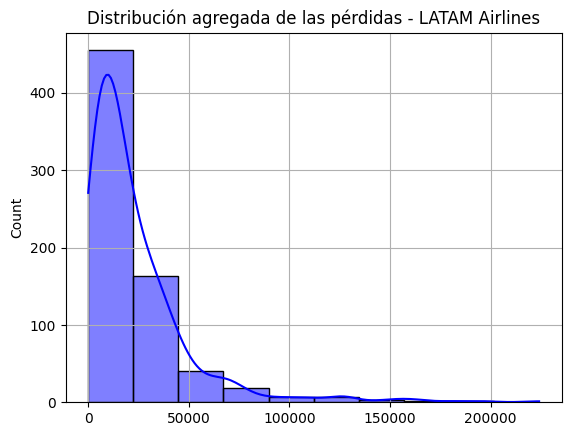

In [ ]:
Freq = df_aerolinea_LATAM.iloc[:,2]
Sev = df_aerolinea_LATAM.iloc[:,3]
LDA = Freq*Sev
ND=len(LDA)
LDA=Freq*Sev
sigmao=np.std(LDA)
uo=np.mean(LDA)


plt.figure()
sns.histplot(LDA, color="blue", bins=10, kde = True)
plt.title("Distribución agregada de las pérdidas - LATAM Airlines")
plt.grid()
plt.show()


In [ ]:
caracterizacion(LDA)

,LI,LS,ND,fi,Marca de clase
0,86.216631,22479.306118,455.0,0.650000,11282.761375
1,22479.306118,44872.395606,163.0,0.232857,33675.850862
2,44872.395606,67265.485094,41.0,0.058571,56068.940350
3,67265.485094,89658.574581,19.0,0.027143,78462.029837
4,89658.574581,112051.664069,7.0,0.010000,100855.119325
5,112051.664069,134444.753556,7.0,0.010000,123248.208813
6,134444.753556,156837.843044,3.0,0.004286,145641.298300
7,156837.843044,179230.932531,2.0,0.002857,168034.387788
8,179230.932531,201624.022019,2.0,0.002857,190427.477275
9,201624.022019,224017.111507,1.0,0.001429,212820.566763


La media de las pérdidas es: 24782.595322844925
La varianza de las pérdidas es: 677383837.8825821
La desviación estándar de las pérdidas es: 26026.59866141909
El limite inferior es  -27270.601999993258
El limite superior es  76835.7926456831
El coeficiente de asimetría es: 3.2305447437878474
El coeficiente de curtosis es: 13.637417001505153


#Mejorar la confiabilidad mediante métodos de integración.

El primer método será muestreo aleatorio con el método de montecarlo.

In [ ]:
import random #Cogemos cinco datos random de los que tenemos
random.seed(42)
XC=np.array(random.choices(LDA, k=5))
XC=np.sort(XC)
print("Los concentradores de información son:", XC)

Los concentradores de información son: [ 6806.52488381  8360.53254474  8596.08509326 14407.03687127
 60535.35062008]


In [ ]:
Box0=[]; Box1=[];Box2=[];Box3=[];Box4=[]
Boxes=[Box0,Box1,Box2,Box3,Box4]
for k in range(len(LDA)):
  d=np.abs(XC-LDA.iloc[k,])/XC #La distancia de un dato a un concentrador
  nc=np.argmin(d)#Numero de la caja donde irá el dato
  #print("La distancia porcentual es de:", d)
  #print("El dato pertenece a la categoria:", nc)
  Boxes[nc].append(LDA.iloc[k,])

# Determinamos el número de datos a muestrear por caja una vez que todas las Boxes están llenas
pm = [] # Vector para almacenar el número de muestras por caja
for j in range(5):
    # Calculamos la proporción de datos en la caja actual
    proportion = len(Boxes[j]) / len(LDA)
    # Escalar esta proporción por la longitud total de LDA para obtener el número de muestras.
    # Usamos round para manejar posibles problemas de punto flotante y lo convertimos a entero.
    num_samples = int(round(proportion * len(LDA)))
    pm.append(num_samples)
pm = np.array(pm) # Convertir a un array de numpy
print("El número de datos a muestrear de cada caja es:", pm)

El número de datos a muestrear de cada caja es: [190  19  56 198 237]


La media de los datos observados es: 23175.426882332642
La media de los datos externos es: 22464.143852274843
El error relativo porcentual es: 3.069125905076779


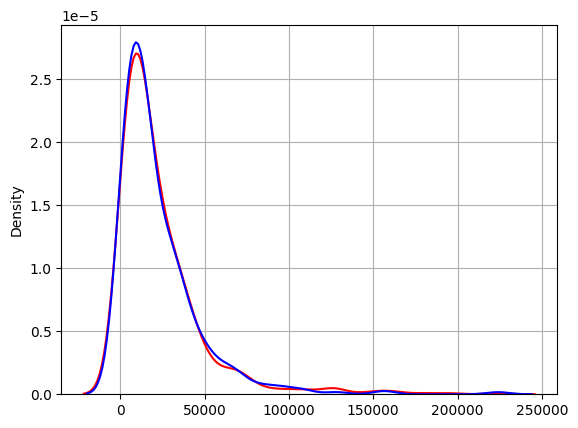

In [ ]:
LDA2=[]

for j in range(5):
    if len(Boxes[j]) > 0:
        LDA2.extend(random.choices(Boxes[j], k=pm[j]))

LDA2=np.array(LDA2)

#Se comprueban las metricas estadisticas
uo=np.mean(LDA)
print("La media de los datos observados es:", uo)
ue=np.mean(LDA2)
print("La media de los datos externos es:", ue)
du=np.abs((uo-ue)/uo)
print("El error relativo porcentual es:", du*100) # Corregido: multiplicado por 100 para porcentaje

plt.figure()
sns.kdeplot(LDA, color="red", label="Datos observados")
sns.kdeplot(LDA2, color="blue", label="Datos externos")
plt.grid()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Asegurarse de que LDA sea un array de numpy o una lista para facilitar la concatenación
# Si LDA es una Serie de Pandas, se convierte a array de numpy
if isinstance(LDA, pd.Series):
    LDA_array = LDA.values
else:
    LDA_array = np.asarray(LDA)

# Seleccionar 300 datos aleatorios de LDA2
# np.random.choice es útil para muestreo aleatorio.
# replace=True permite que el mismo elemento sea seleccionado más de una vez si es necesario,
# pero dado que estamos integrando, y no solo reemplazando, es adecuado.
# Aquí asumimos que no es un problema si los 300 datos se repiten si LDA2 es pequeño,
# pero LDA2 tiene 700 elementos, así que 300 es seguro sin repetición.
# Para evitar repeticiones si la muestra es menor que la población, se usa replace=False
# Sin embargo, random.choice con replace=True es más general si alguna vez se pidiera más elementos que la longitud de LDA2
sampled_data = np.random.choice(LDA2, size=300, replace=False)

# Integrar los datos muestreados a LDA
LDA = np.concatenate((LDA_array, sampled_data))

# Opcionalmente, puedes volver a convertir LDA a una Serie de Pandas si es como se usa habitualmente.
LDA = pd.Series(LDA)

print(f"Se han integrado 300 datos de LDA2 a LDA. El nuevo tamaño de LDA es: {len(LDA)}")

Se han integrado 300 datos de LDA2 a LDA. El nuevo tamaño de LDA es: 1000


In [ ]:
caracterizacion(LDA)

,LI,LS,ND,fi,Marca de clase
0,86.216631,22479.306118,650.0,0.650,11282.761375
1,22479.306118,44872.395606,234.0,0.234,33675.850862
2,44872.395606,67265.485094,61.0,0.061,56068.940350
3,67265.485094,89658.574581,25.0,0.025,78462.029837
4,89658.574581,112051.664069,11.0,0.011,100855.119325
5,112051.664069,134444.753556,8.0,0.008,123248.208813
6,134444.753556,156837.843044,4.0,0.004,145641.298300
7,156837.843044,179230.932531,2.0,0.002,168034.387788
8,179230.932531,201624.022019,2.0,0.002,190427.477275
9,201624.022019,224017.111507,3.0,0.003,212820.566763


La media de las pérdidas es: 24629.042709215795
La varianza de las pérdidas es: 670330947.4413888
La desviación estándar de las pérdidas es: 25890.750229404108
El limite inferior es  -27152.45774959242
El limite superior es  76410.54316802401
El coeficiente de asimetría es: 3.403328849413512
El coeficiente de curtosis es: 15.688734842859695


Lo que se hizo fue incluir 300 datos nuevos a LDA, esto para mejorar la confiabilidad de los datos al tener 1000 en vez de 700, podemos observar cuando imprimimos las nuevas medidas de tendencia de LDA que la variación después de incluir los nuevos datos es muy baja, lo cual es una buena señal porque quiere decir que mejoramos la confiabilidad sin perder la esencia original de nuestros datos, siguen siendo muy afines a la realidad.

In [ ]:
np.random.seed(84) # Seed diferente para el dataset externo
n_observations_e = 800

#Generamos semana ademas de vuelos y overcooking con rangos distintos
semana_e = np.arange(1, n_observations_e + 1)
transacciones_semanales_e = np.random.randint(30, 400, n_observations_e)
frecuencia_e = np.random.randint(0, 40, n_observations_e)

severidad_e = np.random.lognormal(mean=6.0, sigma=0.7, size=n_observations_e) # Distribución de costos ligeramente diferente

# Creamos el df
df_aerolinea_Avianca = pd.DataFrame({
    'Semana': semana_e,
    'Vuelos semanales': transacciones_semanales_e,
    'Overbooking': frecuencia_e,
    'Compensación': severidad_e
})

#Mostramos el df y lo guardamos como excel
display(df_aerolinea_Avianca.head())
XDe=df_aerolinea_Avianca

# Save the DataFrame to an Excel file
df_aerolinea_Avianca.to_excel('df_aerolinea_Avianca.xlsx', index=False)
print("DataFrame 'df_aerolinea' guardado como 'df_aerolinea_LATAM.xlsx'")

,Semana,Vuelos semanales,Overbooking,Compensación
0,1,271,34,139.752455
1,2,375,4,304.076955
2,3,342,19,572.158552
3,4,236,6,633.656358
4,5,139,1,516.419571


DataFrame 'df_aerolinea' guardado como 'df_aerolinea_LATAM.xlsx'


In [ ]:
import numpy as np
import pandas as pd

# 1. Crear copia del DataFrame de LATAM original (700 filas)
df_latam_completo = df_aerolinea_LATAM.copy()
df_latam_completo['Aerolínea'] = 'LATAM'

# 2. Reconstruir los 300 registros simulados agregados a LDA (del paso HwUsP6lYlqxd)
# Para mantener la relación LDA = Overbooking * Compensación:
# Asignamos valores razonables de Overbooking (frecuencia) para estos 300 registros simulados
np.random.seed(42)
simulated_overbooking = np.random.randint(1, 50, size=300)

# La compensación (severidad) será la división de la pérdida simulada (sampled_data) entre la frecuencia simulada
simulated_compensacion = sampled_data / simulated_overbooking

# Crear DataFrame para los 300 registros adicionales
df_latam_simulado = pd.DataFrame({
    'Semana': np.arange(701, 1001),
    'Vuelos semanales': np.random.randint(50, 500, size=300),
    'Overbooking': simulated_overbooking,
    'Compensación': simulated_compensacion,
    'Aerolínea': 'LATAM'
})

# Unir LATAM original con los 300 datos simulados
df_latam_final = pd.concat([df_latam_completo, df_latam_simulado], ignore_index=True)

# 3. Preparar el DataFrame de Avianca (800 filas)
df_avianca_final = df_aerolinea_Avianca.copy()
df_avianca_final['Aerolínea'] = 'Avianca'

# 4. Integrar ambas bases de datos en una sola estructura unificada
df_integrado = pd.concat([df_latam_final, df_avianca_final], ignore_index=True)

# Guardar la base de datos unificada
#df_integrado.to_excel('df_aerolineas_integrado.xlsx', index=False)
print(f"¡Integración completada con éxito!")
print(f"Registros LATAM (Originales + Simulados): {len(df_latam_final)}")
print(f"Registros Avianca: {len(df_avianca_final)}")
print(f"Total registros en base integrada: {len(df_integrado)}")
display(df_integrado.sample(10))

¡Integración completada con éxito!
Registros LATAM (Originales + Simulados): 1000
Registros Avianca: 800
Total registros en base integrada: 1800


,Semana,Vuelos semanales,Overbooking,Compensación,Aerolínea
1085,86,83,19,259.500893,Avianca
1294,295,174,24,858.493050,Avianca
208,209,239,28,449.640532,LATAM
1178,179,199,1,271.604058,Avianca
282,283,289,32,874.961843,LATAM
478,479,191,1,398.947808,LATAM
450,451,176,44,2457.120036,LATAM
1355,356,71,30,270.502067,Avianca
111,112,90,15,1579.122482,LATAM
498,499,354,42,722.965052,LATAM


In [ ]:
#Ahora con el dataset externo
Freqe=XDe.iloc[:,2]; Seve=XDe.iloc[:,3] # Corregidos los índices de las columnas ya que no se cuenta con exactamente las mismas columnas (LI,LS)
LDAe=Freqe*Seve
NDe=len(LDAe)
sigmae=np.std(LDAe)
ue=np.mean(LDAe)
XDe.head()

,Semana,Vuelos semanales,Overbooking,Compensación
0,1,271,34,139.752455
1,2,375,4,304.076955
2,3,342,19,572.158552
3,4,236,6,633.656358
4,5,139,1,516.419571


In [ ]:
caracterizacion(LDAe)

,LI,LS,ND,fi,Marca de clase
0,0.000000,7296.729547,435.0,0.54375,3648.364774
1,7296.729547,14593.459094,214.0,0.26750,10945.094321
2,14593.459094,21890.188641,80.0,0.10000,18241.823868
3,21890.188641,29186.918188,33.0,0.04125,25538.553415
4,29186.918188,36483.647736,16.0,0.02000,32835.282962
5,36483.647736,43780.377283,12.0,0.01500,40132.012509
6,43780.377283,51077.106830,3.0,0.00375,47428.742056
7,51077.106830,58373.836377,5.0,0.00625,54725.471603
8,58373.836377,65670.565924,1.0,0.00125,62022.201151
9,65670.565924,72967.295471,1.0,0.00125,69318.930698


La media de las pérdidas es: 9732.013033473588
La varianza de las pérdidas es: 88441303.8847066
La desviación estándar de las pérdidas es: 9404.323680345471
El limite inferior es  -9076.634327217354
El limite superior es  28540.66039416453
El coeficiente de asimetría es: 2.3853545513158894
El coeficiente de curtosis es: 7.310101319979712


In [ ]:
#Varianza ponderada
EPV=(ND*sigmao**2+NDe*sigmae**2)/(ND+NDe)
print("La ponderación de la varianza es:", EPV)

#Media hipotetica - ponderado de las medias
uh=(ND*uo+NDe*ue)/(ND+NDe)
print("La media hipotetica ponderada es:", uh)

#La varianza de dos variables es:
VHM=(((ND)/(ND+NDe))*uo**2+((NDe)/(ND+NDe))*ue**2)-uh**2
print("La varianza de dos variables es:", VHM)
Cr=ND/(ND+(EPV/VHM))
print("La credibilidad de mis datos es:",Cr*100)
print("La credibilidad de la base de datos externos es del:",(1-Cr)*100)

La ponderación de la varianza es: 387530810.7517121
La media hipotetica ponderada es: 15739.540027436366
La varianza de dos variables es: 48380861.6539669
La credibilidad de mis datos es: 98.86865973284345
La credibilidad de la base de datos externos es del: 1.1313402671565442


LATAM   -> N=1000, media=23050.86, sigma=26972.70
Avianca -> N=800, media=9233.14, sigma=9625.31

EPV = 445357564.56 | VHM = 47143053.71 | K = 9.4469
Credibilidad datos propios:   99.06%
Credibilidad datos externos:  0.94%

Media creíble integrada: 22921.54

Base integrada: 991 datos LATAM + 9 datos Avianca = 1000


,LI,LS,ND,fi,Marca de clase
0,86.216631,22479.306118,652.0,0.652,11282.761375
1,22479.306118,44872.395606,233.0,0.233,33675.850862
2,44872.395606,67265.485094,61.0,0.061,56068.940350
3,67265.485094,89658.574581,24.0,0.024,78462.029837
4,89658.574581,112051.664069,11.0,0.011,100855.119325
5,112051.664069,134444.753556,8.0,0.008,123248.208813
6,134444.753556,156837.843044,4.0,0.004,145641.298300
7,156837.843044,179230.932531,2.0,0.002,168034.387788
8,179230.932531,201624.022019,2.0,0.002,190427.477275
9,201624.022019,224017.111507,3.0,0.003,212820.566763


La media de las pérdidas es: 24539.47035126547
La varianza de las pérdidas es: 667699335.4441087
La desviación estándar de las pérdidas es: 25839.878781528925
El limite inferior es  -27140.28721179238
El limite superior es  76219.22791432332
El coeficiente de asimetría es: 3.4245077069138548
El coeficiente de curtosis es: 15.865042172641836

Error relativo vs LATAM:        0.73%
Error relativo vs media creíble: 0.17%


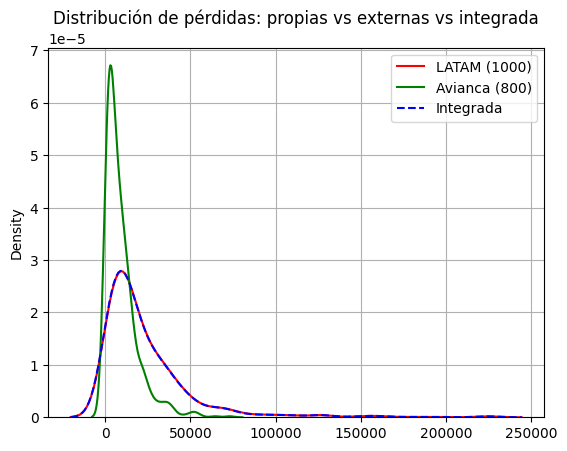

In [ ]:
# ============================================================
# INTEGRACIÓN DE BASES: LATAM (1000 datos) + AVIANCA (800 datos)
# ============================================================

# 1. Recalcular métricas con LDA ya ampliada (700 + 300 = 1000)
LDA_o = np.asarray(LDA)    # Datos propios (LATAM)
LDA_e = np.asarray(LDAe)   # Datos externos (Avianca)

ND, NDe = len(LDA_o), len(LDA_e)
uo, ue = np.mean(LDA_o), np.mean(LDA_e)
sigmao, sigmae = np.std(LDA_o), np.std(LDA_e)

print(f"LATAM   -> N={ND}, media={uo:.2f}, sigma={sigmao:.2f}")
print(f"Avianca -> N={NDe}, media={ue:.2f}, sigma={sigmae:.2f}")

# 2. Credibilidad de Bühlmann
EPV = (ND*sigmao**2 + NDe*sigmae**2) / (ND + NDe)                    # Varianza esperada del proceso
uh  = (ND*uo + NDe*ue) / (ND + NDe)                                  # Media hipotética
VHM = (ND/(ND+NDe))*uo**2 + (NDe/(ND+NDe))*ue**2 - uh**2             # Varianza de las medias
K   = EPV / VHM
Cr  = ND / (ND + K)

print(f"\nEPV = {EPV:.2f} | VHM = {VHM:.2f} | K = {K:.4f}")
print(f"Credibilidad datos propios:   {Cr*100:.2f}%")
print(f"Credibilidad datos externos:  {(1-Cr)*100:.2f}%")

# 3. Media creíble (estimador de credibilidad)
u_cred = Cr*uo + (1-Cr)*ue
print(f"\nMedia creíble integrada: {u_cred:.2f}")

# 4. Construir la base integrada según la credibilidad
np.random.seed(42)
N_total = ND                              # Se mantiene el tamaño de la base propia
n_prop  = int(round(Cr * N_total))        # Datos que aporta LATAM
n_ext   = N_total - n_prop                # Datos que aporta Avianca

muestra_prop = np.random.choice(LDA_o, size=n_prop, replace=False)
muestra_ext  = np.random.choice(LDA_e, size=n_ext,  replace=(n_ext > NDe))

LDA_int = pd.Series(np.concatenate((muestra_prop, muestra_ext)))
print(f"\nBase integrada: {n_prop} datos LATAM + {n_ext} datos Avianca = {len(LDA_int)}")

# 5. Caracterización de la base integrada
caracterizacion(LDA_int)

# 6. Comparación
u_int = np.mean(LDA_int)
print(f"\nError relativo vs LATAM:        {abs((uo - u_int)/uo)*100:.2f}%")
print(f"Error relativo vs media creíble: {abs((u_cred - u_int)/u_cred)*100:.2f}%")

plt.figure()
sns.kdeplot(LDA_o,   color="red",   label="LATAM (1000)")
sns.kdeplot(LDA_e,   color="green", label="Avianca (800)")
sns.kdeplot(LDA_int, color="blue",  label="Integrada", linestyle="--")
plt.title("Distribución de pérdidas: propias vs externas vs integrada")
plt.legend(); plt.grid(); plt.show()

In [ ]:
import pandas as pd
import numpy as np

# 1. Crear una copia del DataFrame de LATAM original (700 filas)
df_latam_completo = df_aerolinea_LATAM.copy()
df_latam_completo['Aerolínea'] = 'LATAM'

# 2. Reconstruir los 300 registros simulados con los datos guardados en 'sampled_data'
# Usamos una semilla para asegurar la reproducibilidad de la asignación
np.random.seed(42)
simulated_overbooking = np.random.randint(1, 50, size=300)
simulated_compensacion = sampled_data / simulated_overbooking

# Generar DataFrame con las 300 filas simuladas adicionales
df_latam_simulado = pd.DataFrame({
    'Semana': np.arange(701, 1001),
    'Vuelos semanales': np.random.randint(50, 500, size=300),
    'Overbooking': simulated_overbooking,
    'Compensación': simulated_compensacion,
    'Aerolínea': 'LATAM'
})

# Combinar la base de LATAM original con la simulada (Total 1000 registros)
df_latam_final = pd.concat([df_latam_completo, df_latam_simulado], ignore_index=True)

# 3. Preparar la base de datos de Avianca (800 filas)
df_avianca_final = df_aerolinea_Avianca.copy()
df_avianca_final['Aerolínea'] = 'Avianca'

# 4. Integrar ambas aerolíneas en una sola base de datos consolidada (Total 1800 registros)
df_integrado = pd.concat([df_latam_final, df_avianca_final], ignore_index=True)

# 5. Exportar la base de datos unificada a un archivo Excel
output_file = 'df_aerolineas_integrado.xlsx'
df_integrado.to_excel(output_file, index=False)

print(f"¡Base de datos integrada creada con éxito!")
print(f"-> Filas de LATAM (700 originales + 300 simuladas): {len(df_latam_final)}")
print(f"-> Filas de Avianca: {len(df_avianca_final)}")
print(f"-> Total de registros en base integrada: {len(df_integrado)}")
print(f"-> Archivo guardado como: '{output_file}'")

# Mostrar una muestra aleatoria de la base integrada
display(df_integrado.sample(10))

¡Base de datos integrada creada con éxito!
-> Filas de LATAM (700 originales + 300 simuladas): 1000
-> Filas de Avianca: 800
-> Total de registros en base integrada: 1800
-> Archivo guardado como: 'df_aerolineas_integrado.xlsx'


,Semana,Vuelos semanales,Overbooking,Compensación,Aerolínea
1085,86,83,19,259.500893,Avianca
1294,295,174,24,858.493050,Avianca
208,209,239,28,449.640532,LATAM
1178,179,199,1,271.604058,Avianca
282,283,289,32,874.961843,LATAM
478,479,191,1,398.947808,LATAM
450,451,176,44,2457.120036,LATAM
1355,356,71,30,270.502067,Avianca
111,112,90,15,1579.122482,LATAM
498,499,354,42,722.965052,LATAM


#Lógica borrosa

Ahora aplicaremos la lógica borrosa para generar matrices de riesgo y para definir el valor financiero que captura el tratamiento del riesgo, así como gases de efecto invernadero

In [ ]:
XD0 = df_integrado
Xf = np.array(XD0.iloc[:, 2])  # Número de eventos de riesgo (Overbooking es columna índice 2)
Xs = np.array(XD0.iloc[:, 3])  # Severidad de los eventos (Compensación es columna índice 3)

# Buscamos los Fuzzy Sets Xf
XCf, ncf = clusterizacion(Xf) # XCf: Indica los concentradores de información - ncf: Cluster Pertenence
lbf = ['MuyPocoFrecuente', 'PocoFrecuente', 'Normal', 'Frecuente', 'MuyFrecuente']

XCs, ncs = clusterizacion(Xs)
lbs = ['Insignif', 'Menor', 'Significativo', 'Mayor', 'Severo']

sigmaf = []
sigmas = [] # Bases para la variable

for i in range(5):
    sigmaf.append(np.sqrt((np.sum((XCf - XCf[i])**2) / 4)))
    sigmas.append(np.sqrt((np.sum((XCs - XCs[i])**2) / 4)))

print("Los clusters de frecuencia son:", XCf)
print("Los clusters de Costo-Atención (Severidad):", XCs)

Los clusters de frecuencia son: [ 1.6755048  23.38945915 14.00425544 29.8995862  37.48620759]
Los clusters de Costo-Atención (Severidad): [  262.97102051  1450.02233034  3742.58319796 11692.15710822
 53089.01511873]


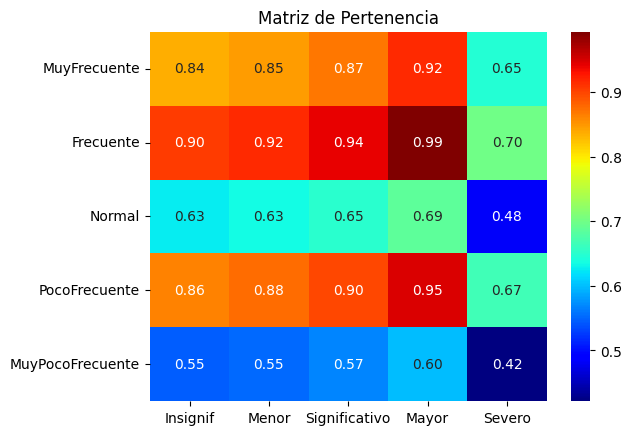

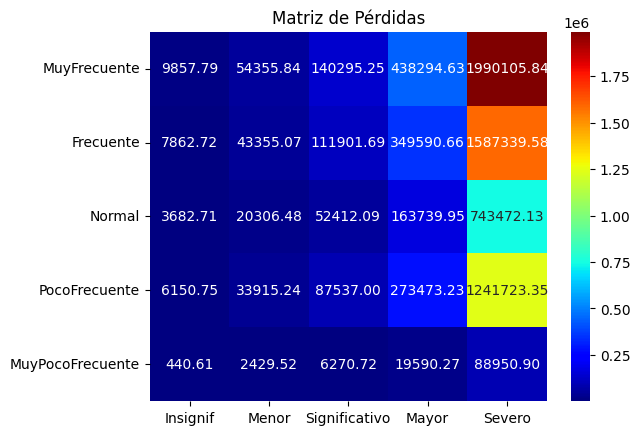

El costo de este paciente al año es: 336000
El costo real de este paciente es: 282404.42976801365


In [ ]:
# Definimos un paciente de prueba para los cálculos de costo tradicional
Xfp = 28  # Frecuencia representativa (ejemplo: 28 eventos de riesgo)
Xsp = 12000  # Severidad representativa (ejemplo: severidad de 12000)

# Calculamos la Matriz de Pertenencia (MVP) usando una función gaussiana
# para cada combinación de las 5 categorías de frecuencia y severidad.
MVP = np.zeros((5, 5))
for i in range(5):
    for j in range(5):
        # Evaluamos la pertenencia del paciente de prueba a los clusters
        pert_f = np.exp(-0.5 * ((Xfp - XCf[i]) / sigmaf[i])**2) if sigmaf[i] > 0 else 0
        pert_s = np.exp(-0.5 * ((Xsp - XCs[j]) / sigmas[j])**2) if sigmas[j] > 0 else 0
        # La pertenencia conjunta (intersección) se suele modelar como el producto
        MVP[i, j] = pert_f * pert_s

# Visualización de Matriz de Pertenencia
plt.figure()
# Solo visualización: se voltean las filas para que el riesgo más alto quede arriba a la derecha
sns.heatmap(np.flipud(MVP), annot=True, fmt='.2f', cmap='jet', xticklabels=lbs, yticklabels=lbf[::-1])
plt.title('Matriz de Pertenencia')
plt.show()

# Construimos la Matriz de Pérdida
MP = np.outer(XCf, XCs)

plt.figure()
sns.heatmap(np.flipud(MP), annot=True, fmt='.2f', cmap='jet', xticklabels=lbs, yticklabels=lbf[::-1])
plt.title('Matriz de Pérdidas')
plt.show()

# ¿Cuánto es el costo normal de la atención a un evento de riesgo?
# Multiplicación Simple
LDA = Xfp * Xsp
print("El costo de este paciente al año es:", LDA)

# ¿Cuánto es el costo del evento de riesgo teniendo en cuenta distribuciones?
# Convolución - Carga con la estructura de las distribuciones
LDAm = np.sum(MVP * MP) / np.sum(MVP) if np.sum(MVP) > 0 else 0
print("El costo real de este paciente es:", LDAm)

# Clasificamos pacientes por frecuencia (fila) - severidad (columna)
ME = np.zeros((5, 5))
for k in range(len(XD0)):
    # Tomamos el índice de pertenencia de cada dato
    fila = int(ncf[k][0])
    columna = int(ncs[k][0])
    ME[fila, columna] = ME[fila, columna] + 1

In [ ]:
# Potencial de captura
VCF = (LDA - LDAm)*1000 # Cuanta plata me ahorro por este evento de riesgo gestionándolo con todos los demás
print("El valor financiero capturado es:", VCF)

CTCO2 = 90 # Costo de tonelada capturada
GEI = (VCF / CTCO2) #Multiplicado por mil porque las cifras están en miles de dólares.
print("La cantidad de toneladas capturadas en este evento de riesgo es:", GEI)

El valor financiero capturado es: 53595570.23198635
La cantidad de toneladas capturadas en este evento de riesgo es: 595506.3359109594


In [ ]:
NG = float(input("Ingresar el Nivel de Gestión "))

# Matriz de Impacto (MI) de 5x5, según la importancia de la escala de 1 a 5
MI = np.zeros((5, 5))
for i in range(5):
    for j in range(5):
        MI[i, j] = (i + j) / 2 + 1  # Nivel de impacto promedio

# Matriz de Gestión
MG = MI.copy().astype(float)
MG[(MG > 1) & (MG < 5)] *= NG # Corregido: se multiplica por NG, igual que en la celda de escenarios
print("La matriz de gestión es (riesgo alto arriba a la derecha):\n", np.flipud(MG))

ER = np.mean(MI / MG)
print("La exposición al riesgo es:", ER)

# Costo del paciente incluyendo los niveles de riesgo
LDAm4 = np.sum(MI * MP * MVP * ME) / np.sum(MVP * ME * MG)

# Valores ilustrativos
LDAm2 = LDAm * 1.1  # Valor estimado de eventos de pérdida
LDAm3 = LDAm * 1.25 # Valor estimado de nivel de impacto

# Distribución de Referencia (NG = 1 -> MG = MI) - Exposición Riesgo 100%
LDAm0 = np.sum(MI * MP * MVP * ME) / np.sum(MVP * ME * MI)

print("El costo del paciente tradicional es:", LDA)
print("El valor de referencia es (NG=1):", LDAm0)
print("El costo del paciente con matriz de Pertenencia es:", LDAm)
print("El costo del paciente con Eventos de Pérdida:", LDAm2)
print("El costo del paciente con Nivel de Impacto es:", LDAm3)
print("El costo real del paciente con Nivel de Gestión (NG) es:", LDAm4)

# Estimación de Captura de Gases de Efecto Invernadero
Vcapt = LDAm0 - LDAm4
print("El valor capturado financiero es:", Vcapt)

Ingresar el Nivel de Gestión 1.5
La matriz de gestión es (riesgo alto arriba a la derecha):
 [[4.5  5.25 6.   6.75 5.  ]
 [3.75 4.5  5.25 6.   6.75]
 [3.   3.75 4.5  5.25 6.  ]
 [2.25 3.   3.75 4.5  5.25]
 [1.   2.25 3.   3.75 4.5 ]]
La exposición al riesgo es: 0.6933333333333332
El costo del paciente tradicional es: 336000
El valor de referencia es (NG=1): 77608.55348460165
El costo del paciente con matriz de Pertenencia es: 282404.42976801365
El costo del paciente con Eventos de Pérdida: 310644.872744815
El costo del paciente con Nivel de Impacto es: 353005.5372100171
El costo real del paciente con Nivel de Gestión (NG) es: 52500.72900682146
El valor capturado financiero es: 25107.824477780196


--------------------
El nivel de gestión es: 1.0
La matriz de gestión es (riesgo alto arriba a la derecha):
 [[3.  3.5 4.  4.5 5. ]
 [2.5 3.  3.5 4.  4.5]
 [2.  2.5 3.  3.5 4. ]
 [1.5 2.  2.5 3.  3.5]
 [1.  1.5 2.  2.5 3. ]]
La exposición al riesgo es: 1.0
El número de eventos de pérdida esperados de referencia son: 937
El coeficiente de asimetría de referencia es: 20.971355927154285
El número de eventos de pérdida esperados gestionados son: 937
El coeficiente de asimetría gestionado es: 20.971355927154285
Número de eventos de pérdida movilizados: 0
El valor capturado financiero es:  0.0
El número de toneladas capturadas es:  0.0
El costo real de gestión es:  0.0
--------------------
El nivel de gestión es: 1.1
La matriz de gestión es (riesgo alto arriba a la derecha):
 [[3.3  3.85 4.4  4.95 5.  ]
 [2.75 3.3  3.85 4.4  4.95]
 [2.2  2.75 3.3  3.85 4.4 ]
 [1.65 2.2  2.75 3.3  3.85]
 [1.   1.65 2.2  2.75 3.3 ]]
La exposición al riesgo es: 0.9163636363636363
El número de eventos de pérdida

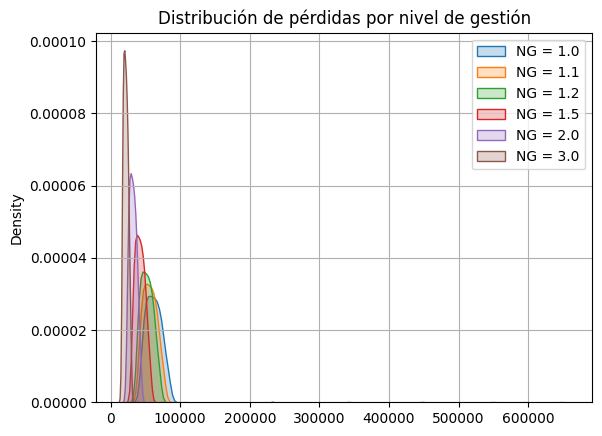

El valor capturado financiero es promedio: 40535.259042482176


In [ ]:
NG = np.array([1, 1.1, 1.2, 1.5, 2, 3]) # Incrementar el presupuesto para gestión - matriz de gestión
plt.figure()
# Convertimos sigmaf y sigmas a numpy arrays para permitir operaciones vectorizadas
sigmaf_arr = np.array(sigmaf)
sigmas_arr = np.array(sigmas)

for ng in NG:
    print("--------------------")
    print("El nivel de gestión es:", ng)

    # Creamos la matriz de gestión
    MG = MI.copy().astype(float)
    MG[(MG > 1) & (MG < 5)] *= ng

    print("La matriz de gestión es (riesgo alto arriba a la derecha):\n", np.flipud(MG))
    ER = np.mean(MI / MG)
    print("La exposición al riesgo es:", ER)

    LDAm5 = []

    for k in range(len(XD0)):
        VPf = np.exp(-0.5 * ((XCf - Xf[k]) / sigmaf_arr)**2) # Valor de Pertenencia a la Frecuencia
        VPs = np.exp(-0.5 * ((XCs - Xs[k]) / sigmas_arr)**2) # Valor de Pertenencia a la Severidad
        MVPk = np.outer(VPf, VPs) # Corregido: nombre distinto para no sobrescribir el MVP global

        LDAm5.append(np.sum(MI * MP * MVPk * ME) / np.sum(MVPk * ME * MG))

    LDAm5 = np.array(LDAm5) # Esta es la distribución pérdidas para los pacientes por nivel de gestión

    if ng == 1:
        LDAm0ref = LDAm5 # Distribución de Referencia - Exposición Riesgo 100%

    # Caracterizamos los parámetros de riesgo - Distribución de Referencia NG = 1
    um0 = np.mean(LDAm0ref) # media de la distribución
    NEL0 = len(np.where(LDAm0ref < um0)[0])
    CAS0 = stats.skew(LDAm0ref)

    print("El número de eventos de pérdida esperados de referencia son:", NEL0)
    print("El coeficiente de asimetría de referencia es:", CAS0)

    # Caracterizamos la distribución de pérdidas gestionada
    umg = np.mean(LDAm5)
    NELg = len(np.where(LDAm5 < umg)[0])
    CASg = stats.skew(LDAm5)
    print("El número de eventos de pérdida esperados gestionados son:", NELg)
    print("El coeficiente de asimetría gestionado es:", CASg)

    # Números de eventos de pérdida movilizados
    NEPm = NELg - NEL0
    print("Número de eventos de pérdida movilizados:", NEPm)

    # El ahorro que se logra con la movilización es el siguiente:
    CPerdida = np.mean(Xs) # Costo de una pérdida promedio
    VCapt = NEPm * CPerdida # Cuanto me ahorro movilizando pacientes hacia la categoría de pacientes sanos
    print("El valor capturado financiero es: ", VCapt)

    # El número total de toneladas de carbono potenciales son:
    CCO2 = 90 # USD/Ton: Me pagarían por capturar gases de efecto invernadero
    TC = VCapt / CCO2 # Toneladas de carbono que evito cuando evito que los eventos de riesgo se presenten
    print("El número de toneladas capturadas es: ", TC)

    # Cuánta plata me cuesta la gestión
    CGP = 75.92 # Esto me cuesta la atención de cada evento de riesgo
    CGT = NEPm * CGP
    print("El costo real de gestión es: ", CGT)

    sns.kdeplot(LDAm5, fill=True, label=f"NG = {ng}") # Corregido: label para que funcione plt.legend()

plt.title("Distribución de pérdidas por nivel de gestión") # Corregido: título general, no solo el último ng
plt.legend()
plt.grid()
plt.show()

Vcapt = LDAm0ref - LDAm5 # Corregido: se compara contra la distribución de referencia, no el escalar LDAm0
print("El valor capturado financiero es promedio:", np.mean(Vcapt))